In [ ]:
# ==============================================================================
# Step 1: Download & Load Credit Card Fraud Dataset
# ==============================================================================
import os
import pandas as pd
import numpy as np
import kagglehub

# 1. Download dataset via KaggleHub
print("Downloading / Checking Kaggle Dataset...")
dataset_path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
csv_path = os.path.join(dataset_path, "creditcard.csv")

# 2. Load into DataFrame
df_raw = pd.read_csv(csv_path)

# 3. Print basic summary
print("\n" + "=" * 50)
print("DATASET LOADED SUCCESSFULLY")
print("=" * 50)
print(f"Total Rows: {len(df_raw):,}")
print(f"Total Columns: {len(df_raw.columns)}")
print(f"Columns list: {list(df_raw.columns[:5])} ... {list(df_raw.columns[-3:])}")
print(f"Fraud Count: {df_raw['Class'].sum():,} ({df_raw['Class'].mean()*100:.3f}%)")
print("=" * 50)

# Display first 5 rows
df_raw.head()


Using Colab cache for faster access to the 'creditcardfraud' dataset.

DATASET LOADED SUCCESSFULLY
Total Rows: 284,807
Total Columns: 31
Columns list: ['Time', 'V1', 'V2', 'V3', 'V4'] ... ['V28', 'Amount', 'Class']
Fraud Count: 492 (0.173%)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
# ==============================================================================
# Step 2: Temporal Proximity Analysis (Justification for Sequences)
# ==============================================================================

# 1. Sort by Time to create a clean chronological stream
df = df_raw.sort_values(by="Time").reset_index(drop=True).copy()

# 2. Calculate time difference between consecutive transactions
df["delta_t"] = df["Time"].diff().fillna(0)

# 3. How clustered is the fraud?
# We check if fraud events happen "close" to each other in time
fraud_indices = df[df["Class"] == 1].index
# Time difference between current fraud and previous fraud
fraud_bursts = df.loc[fraud_indices, "Time"].diff().dropna()

print(f"--- Temporal Statistics ---")
print(f"Average time between all transactions: {df['delta_t'].mean():.2f} seconds")
print(f"Median time between all transactions: {df['delta_t'].median():.2f} seconds")

print(f"\n--- Fraud Burstiness ---")
print(f"Number of fraud events: {len(fraud_indices)}")
print(f"Percentage of fraud occurring within 60s of another fraud: {(fraud_bursts <= 60).mean()*100:.2f}%")
print(f"Percentage of fraud occurring within 5 mins (300s) of another fraud: {(fraud_bursts <= 300).mean()*100:.2f}%")

# Preview if fraud happens in 'bunches'
print("\nFirst 10 fraud events and their time gap to the previous one:")
display(df.loc[fraud_indices[:10], ["Time", "delta_t", "Amount", "Class"]])


--- Temporal Statistics ---
Average time between all transactions: 0.61 seconds
Median time between all transactions: 0.00 seconds

--- Fraud Burstiness ---
Number of fraud events: 492
Percentage of fraud occurring within 60s of another fraud: 37.47%
Percentage of fraud occurring within 5 mins (300s) of another fraud: 67.82%

First 10 fraud events and their time gap to the previous one:


,Time,delta_t,Amount,Class
541,406.0,0.0,0.00,1
623,472.0,0.0,529.00,1
4919,4462.0,0.0,239.93,1
6108,6986.0,0.0,59.00,1
6329,7519.0,5.0,1.00,1
6331,7526.0,4.0,1.00,1
6333,7535.0,6.0,1.00,1
6336,7543.0,5.0,1.00,1
6339,7551.0,0.0,1.00,1
6426,7610.0,2.0,1.00,1


In [ ]:
from sklearn.preprocessing import StandardScaler

# 1. Select features (All V1-V28 and Amount)
# We exclude 'Time' because it's a raw counter, and 'Class' is our target
features = [col for col in df.columns if col not in ['Time', 'Class', 'delta_t']]
X_raw = df[features].values
y_raw = df['Class'].values

# 2. Standardize features
# Scaling is crucial for Transformer/RNN convergence
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print(f"Features Scaled: {X_scaled.shape}")
print(f"Target Distribution: {np.bincount(y_raw)}")

# ==============================================================================
# Step 4: Sequence Construction (Sliding Window)
# ==============================================================================

def create_sequences(data, target, window_size=10):
    """
    Creates overlapping sequences from tabular data.
    Input: (n_samples, n_features)
    Output: (n_sequences, window_size, n_features)
    """
    X_seq, y_seq = [], []
    for i in range(len(data) - window_size):
        X_seq.append(data[i : i + window_size])
        # The label for the sequence is the label of the LAST transaction
        y_seq.append(target[i + window_size - 1])

    return np.array(X_seq), np.array(y_seq)

# We use a window_size of 10 (looking at the last 10 transactions)
WINDOW_SIZE = 10
X_s, y_s = create_sequences(X_scaled, y_raw, window_size=WINDOW_SIZE)

print(f"Sequence Shape (Samples, Window, Features): {X_s.shape}")
print(f"Label Shape: {y_s.shape}")


Features Scaled: (284807, 29)
Target Distribution: [284315    492]
Sequence Shape (Samples, Window, Features): (284797, 10, 29)
Label Shape: (284797,)


In [ ]:
# ==============================================================================
# Step 5: Chronological Split and Leakage-Safe Scaling
# ==============================================================================
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Start from the raw dataframe and sort chronologically
df_seq = df_raw.sort_values("Time").reset_index(drop=True).copy()

# Select model features and target
feature_cols = [col for col in df_seq.columns if col not in ["Time", "Class"]]
X_all = df_seq[feature_cols].to_numpy(dtype=np.float32)
y_all = df_seq["Class"].to_numpy(dtype=np.int64)

# Chronological split boundaries: 70% train, 15% validation, 15% test
n = len(df_seq)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Fit the scaler on training rows only
scaler = StandardScaler()
X_train_rows = scaler.fit_transform(X_all[:train_end]).astype(np.float32)
X_val_rows = scaler.transform(X_all[train_end:val_end]).astype(np.float32)
X_test_rows = scaler.transform(X_all[val_end:]).astype(np.float32)

y_train_rows = y_all[:train_end]
y_val_rows = y_all[train_end:val_end]
y_test_rows = y_all[val_end:]

print("Row-level chronological split:")
print(f"Train: {len(y_train_rows):,} rows | fraud={int(y_train_rows.sum())}")
print(f"Validation: {len(y_val_rows):,} rows | fraud={int(y_val_rows.sum())}")
print(f"Test: {len(y_test_rows):,} rows | fraud={int(y_test_rows.sum())}")

# Construct sequences independently within each split.
# This prevents windows from crossing split boundaries.
def make_sequences(features, labels, window_size=10):
    X_seq, y_seq = [], []
    for end in range(window_size - 1, len(features)):
        start = end - window_size + 1
        X_seq.append(features[start:end + 1])
        y_seq.append(labels[end])
    return np.asarray(X_seq, dtype=np.float32), np.asarray(y_seq, dtype=np.int64)

WINDOW_SIZE = 10
X_train_seq, y_train_seq = make_sequences(X_train_rows, y_train_rows, WINDOW_SIZE)
X_val_seq, y_val_seq = make_sequences(X_val_rows, y_val_rows, WINDOW_SIZE)
X_test_seq, y_test_seq = make_sequences(X_test_rows, y_test_rows, WINDOW_SIZE)

print("\nSequence-level shapes and class counts:")
for name, X_part, y_part in [
    ("Train", X_train_seq, y_train_seq),
    ("Validation", X_val_seq, y_val_seq),
    ("Test", X_test_seq, y_test_seq),
]:
    print(
        f"{name}: X={X_part.shape}, y={y_part.shape}, "
        f"fraud={int(y_part.sum())}, non-fraud={int((y_part == 0).sum())}"
    )


Row-level chronological split:
Train: 199,364 rows | fraud=384
Validation: 42,721 rows | fraud=56
Test: 42,722 rows | fraud=52

Sequence-level shapes and class counts:
Train: X=(199355, 10, 29), y=(199355,), fraud=384, non-fraud=198971
Validation: X=(42712, 10, 29), y=(42712,), fraud=56, non-fraud=42656
Test: X=(42713, 10, 29), y=(42713,), fraud=52, non-fraud=42661


In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# 1. Prepare DataLoaders
# Convert numpy arrays to PyTorch tensors
train_ds = TensorDataset(torch.from_numpy(X_train_seq), torch.from_numpy(y_train_seq))
val_ds = TensorDataset(torch.from_numpy(X_val_seq), torch.from_numpy(y_val_seq))

# Use a batch size that fits in GPU memory
train_loader = DataLoader(train_ds, batch_size=2048, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=2048, shuffle=False)

# 2. Define the LSTM Classifier
class LSTMClassifier(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size=1):
        super(LSTMClassifier, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # x shape: (batch, seq_len, features)
        lstm_out, _ = self.lstm(x)
        # Take the last hidden state for classification
        last_out = lstm_out[:, -1, :]
        out = self.fc(last_out)
        return out # Returns raw logits

# Hyperparameters
INPUT_SIZE = 29
HIDDEN_SIZE = 64
NUM_LAYERS = 2
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = LSTMClassifier(INPUT_SIZE, HIDDEN_SIZE, NUM_LAYERS).to(device)

# 3. Handle Class Imbalance
# Calculate weight: (negative samples / positive samples)
pos_weight = torch.tensor([float(len(y_train_seq) - y_train_seq.sum()) / y_train_seq.sum()]).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(f"Model initialized on {device}")
print(f"BCEWithLogitsLoss pos_weight: {pos_weight.item():.2f}")


Model initialized on cpu
BCEWithLogitsLoss pos_weight: 518.15


In [9]:
import math

class TransformerClassifier(nn.Module):
    def __init__(self, input_size, d_model, nhead, num_layers, dim_feedforward=128, dropout=0.1):
        super(TransformerClassifier, self).__init__()
        # 1. Input Projection: Transform 29 features to d_model size
        self.input_projection = nn.Linear(input_size, d_model)

        # 2. Positional Encoding: Transformer needs to know the order of transactions
        self.pos_encoder = nn.Parameter(torch.zeros(1, 10, d_model)) # 10 is our window size

        # 3. Transformer Encoder Layers
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # 4. Classification Head
        self.fc = nn.Linear(d_model, 1)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x shape: (batch, seq_len, features)
        x = self.input_projection(x) # (batch, 10, d_model)
        x = x + self.pos_encoder      # Add position info

        x = self.transformer_encoder(x)

        # Global Average Pooling or taking the last token
        # Here we take the mean across the sequence dimension
        x = x.mean(dim=1)

        x = self.dropout(x)
        logits = self.fc(x)
        return logits

# Initialize Transformer
D_MODEL = 64
NHEAD = 4 # D_MODEL must be divisible by NHEAD
NUM_TRANSFORMER_LAYERS = 2

transformer_model = TransformerClassifier(
    input_size=INPUT_SIZE,
    d_model=D_MODEL,
    nhead=NHEAD,
    num_layers=NUM_TRANSFORMER_LAYERS
).to(device)

print("Transformer Model Initialized.")


Transformer Model Initialized.


In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report
import numpy as np

# 1. Ensure Device (GPU if available)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active training device: {device}")

# 2. Prepare PyTorch DataLoaders (including Test set)
train_ds = TensorDataset(torch.from_numpy(X_train_seq), torch.from_numpy(y_train_seq).float())
val_ds   = TensorDataset(torch.from_numpy(X_val_seq), torch.from_numpy(y_val_seq).float())
test_ds  = TensorDataset(torch.from_numpy(X_test_seq), torch.from_numpy(y_test_seq).float())

train_loader = DataLoader(train_ds, batch_size=2048, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=2048, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=2048, shuffle=False)

# 3. Training & Evaluation Engine
def train_and_evaluate(model, model_name, epochs=10, lr=0.001):
    model = model.to(device)
    pos_weight = torch.tensor([float(len(y_train_seq) - y_train_seq.sum()) / y_train_seq.sum()]).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    best_val_prauc = 0.0
    best_weights = None

    print(f"\n================ Training {model_name} ================")
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            logits = model(X_batch).squeeze(-1)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(y_batch)

        train_loss = total_loss / len(train_ds)

        # Validation Phase
        model.eval()
        val_preds, val_targets = [], []
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                logits = model(X_batch).squeeze(-1)
                probs = torch.sigmoid(logits).cpu().numpy()
                val_preds.extend(probs)
                val_targets.extend(y_batch.numpy())

        val_preds = np.array(val_preds)
        val_targets = np.array(val_targets)
        val_prauc = average_precision_score(val_targets, val_preds)
        val_rocauc = roc_auc_score(val_targets, val_preds)

        print(f"Epoch {epoch:02d}/{epochs:02d} | Train Loss: {train_loss:.4f} | Val PR-AUC: {val_prauc:.4f} | Val ROC-AUC: {val_rocauc:.4f}")

        if val_prauc > best_val_prauc:
            best_val_prauc = val_prauc
            best_weights = model.state_dict().copy()

    # Load best model for Test evaluation
    model.load_state_dict(best_weights)
    model.eval()
    test_preds, test_targets = [], []
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch = X_batch.to(device)
            logits = model(X_batch).squeeze(-1)
            probs = torch.sigmoid(logits).cpu().numpy()
            test_preds.extend(probs)
            test_targets.extend(y_batch.numpy())

    test_preds = np.array(test_preds)
    test_targets = np.array(test_targets)
    test_prauc = average_precision_score(test_targets, test_preds)
    test_rocauc = roc_auc_score(test_targets, test_preds)

    print(f"\n--- Final Test Results for {model_name} ---")
    print(f"Test PR-AUC:  {test_prauc:.4f}")
    print(f"Test ROC-AUC: {test_rocauc:.4f}")

    return model, test_preds

# 4. Run Training for LSTM
lstm_model = LSTMClassifier(input_size=29, hidden_size=64, num_layers=2)
trained_lstm, lstm_test_preds = train_and_evaluate(lstm_model, "LSTM Classifier", epochs=10, lr=0.001)

# 5. Run Training for Transformer
transformer_model = TransformerClassifier(input_size=29, d_model=64, nhead=4, num_layers=2)
trained_transformer, trans_test_preds = train_and_evaluate(transformer_model, "Transformer Classifier", epochs=10, lr=0.001)


Active training device: cpu

================ Training LSTM Classifier ================
Epoch 01/10 | Train Loss: 0.8516 | Val PR-AUC: 0.8155 | Val ROC-AUC: 0.9663
Epoch 02/10 | Train Loss: 0.3695 | Val PR-AUC: 0.8539 | Val ROC-AUC: 0.9796
Epoch 03/10 | Train Loss: 0.2803 | Val PR-AUC: 0.8551 | Val ROC-AUC: 0.9803
Epoch 04/10 | Train Loss: 0.2380 | Val PR-AUC: 0.8553 | Val ROC-AUC: 0.9798
Epoch 05/10 | Train Loss: 0.1928 | Val PR-AUC: 0.8559 | Val ROC-AUC: 0.9726
Epoch 06/10 | Train Loss: 0.1532 | Val PR-AUC: 0.8424 | Val ROC-AUC: 0.9712
Epoch 07/10 | Train Loss: 0.1250 | Val PR-AUC: 0.8238 | Val ROC-AUC: 0.9765
Epoch 08/10 | Train Loss: 0.1106 | Val PR-AUC: 0.8537 | Val ROC-AUC: 0.9757
Epoch 09/10 | Train Loss: 0.0808 | Val PR-AUC: 0.8451 | Val ROC-AUC: 0.9757
Epoch 10/10 | Train Loss: 0.0645 | Val PR-AUC: 0.8390 | Val ROC-AUC: 0.9777

--- Final Test Results for LSTM Classifier ---
Test PR-AUC:  0.7585
Test ROC-AUC: 0.9688

================ Training Transformer Classifier ============

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from sklearn.metrics import average_precision_score, roc_auc_score

# ==============================================================================
# Step 6: Hybrid Model (LSTM with Temporal Self-Attention)
# ==============================================================================

class LSTMAttentionClassifier(nn.Module):
    def __init__(self, input_size=29, hidden_size=64, num_layers=2, dropout=0.2):
        super(LSTMAttentionClassifier, self).__init__()
        self.lstm = nn.LSTM(
            input_size,
            hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        # Additive Attention mechanism over sequence steps
        self.attention_query = nn.Linear(hidden_size, 1)

        # Classification head
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        # x shape: (batch_size, seq_len, input_size)
        lstm_out, _ = self.lstm(x) # (batch_size, seq_len, hidden_size)

        # Calculate attention weights per timestep
        attn_scores = self.attention_query(lstm_out) # (batch_size, seq_len, 1)
        attn_weights = torch.softmax(attn_scores, dim=1) # Normalized across timesteps

        # Context vector as weighted sum of timesteps
        context_vector = torch.sum(attn_weights * lstm_out, dim=1) # (batch_size, hidden_size)

        logits = self.classifier(context_vector)
        return logits

# Initialize and train Hybrid Model
hybrid_model = LSTMAttentionClassifier(input_size=29, hidden_size=64, num_layers=2)
trained_hybrid, hybrid_test_preds = train_and_evaluate(
    hybrid_model,
    "Hybrid (LSTM + Attention)",
    epochs=10,
    lr=0.001
)

# ==============================================================================
# Step 7: Ensemble Evaluation (Soft Voting)
# ==============================================================================
ensemble_preds = (lstm_test_preds + hybrid_test_preds) / 2.0
test_targets = y_test_seq

ensemble_prauc = average_precision_score(test_targets, ensemble_preds)
ensemble_rocauc = roc_auc_score(test_targets, ensemble_preds)

print("\n================ Ensemble Comparison ================")
print(f"1. Standalone LSTM PR-AUC:      {average_precision_score(test_targets, lstm_test_preds):.4f}")
print(f"2. Hybrid (LSTM+Attn) PR-AUC:   {average_precision_score(test_targets, hybrid_test_preds):.4f}")
print(f"3. Ensemble (LSTM+Hybrid) PR-AUC:{ensemble_prauc:.4f}")
print(f"Ensemble Test ROC-AUC:          {ensemble_rocauc:.4f}")



================ Training Hybrid (LSTM + Attention) ================
Epoch 01/10 | Train Loss: 1.2245 | Val PR-AUC: 0.1994 | Val ROC-AUC: 0.9046
Epoch 02/10 | Train Loss: 0.6167 | Val PR-AUC: 0.5834 | Val ROC-AUC: 0.9496
Epoch 03/10 | Train Loss: 0.5012 | Val PR-AUC: 0.7363 | Val ROC-AUC: 0.9617
Epoch 04/10 | Train Loss: 0.3901 | Val PR-AUC: 0.8170 | Val ROC-AUC: 0.9580
Epoch 05/10 | Train Loss: 0.3027 | Val PR-AUC: 0.8296 | Val ROC-AUC: 0.9717
Epoch 06/10 | Train Loss: 0.2596 | Val PR-AUC: 0.7865 | Val ROC-AUC: 0.9740
Epoch 07/10 | Train Loss: 0.1985 | Val PR-AUC: 0.8057 | Val ROC-AUC: 0.9791
Epoch 08/10 | Train Loss: 0.2102 | Val PR-AUC: 0.8026 | Val ROC-AUC: 0.9659
Epoch 09/10 | Train Loss: 0.1410 | Val PR-AUC: 0.8248 | Val ROC-AUC: 0.9671
Epoch 10/10 | Train Loss: 0.1003 | Val PR-AUC: 0.7980 | Val ROC-AUC: 0.9478

--- Final Test Results for Hybrid (LSTM + Attention) ---
Test PR-AUC:  0.7600
Test ROC-AUC: 0.9535

================ Ensemble Comparison ================
1. Standalone L

--- Temporal Attention Weight Distribution across Window Steps (t-9 to t) ---
Step 01 [        t-9]: Fraud Attention = 0.0071 | Normal Attention = 0.0337
Step 02 [        t-8]: Fraud Attention = 0.0067 | Normal Attention = 0.0267
Step 03 [        t-7]: Fraud Attention = 0.0066 | Normal Attention = 0.0231
Step 04 [        t-6]: Fraud Attention = 0.0064 | Normal Attention = 0.0238
Step 05 [        t-5]: Fraud Attention = 0.0075 | Normal Attention = 0.0311
Step 06 [        t-4]: Fraud Attention = 0.0108 | Normal Attention = 0.0504
Step 07 [        t-3]: Fraud Attention = 0.0205 | Normal Attention = 0.0891
Step 08 [        t-2]: Fraud Attention = 0.0364 | Normal Attention = 0.1506
Step 09 [        t-1]: Fraud Attention = 0.0545 | Normal Attention = 0.2321
Step 10 [t (Current)]: Fraud Attention = 0.8435 | Normal Attention = 0.3394


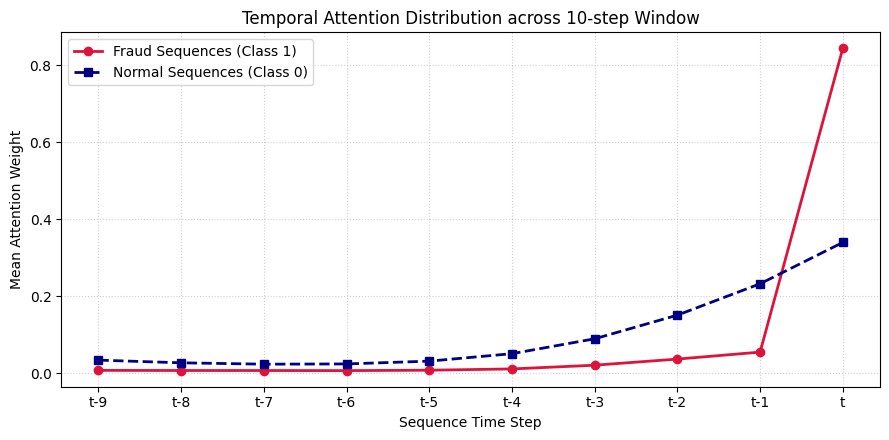

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# ==============================================================================
# Step 8: Temporal Attention Weight Extraction (XAI)
# ==============================================================================

def extract_attention_weights(model, X_seq_data, device):
    """
    Extracts step-wise attention distributions from the Hybrid model.
    """
    model.eval()
    all_weights = []

    with torch.no_grad():
        # Pass data through LSTM and attention layer
        x_tensor = torch.from_numpy(X_seq_data).to(device)
        lstm_out, _ = model.lstm(x_tensor)
        attn_scores = model.attention_query(lstm_out)
        attn_weights = torch.softmax(attn_scores, dim=1).squeeze(-1) # (batch, seq_len)
        all_weights = attn_weights.cpu().numpy()

    return all_weights

# Extract weights for the test set
attn_weights_test = extract_attention_weights(trained_hybrid, X_test_seq, device)

# Separate fraud and non-fraud sequence attention
fraud_mask = (y_test_seq == 1)
fraud_attn_mean = np.mean(attn_weights_test[fraud_mask], axis=0)
normal_attn_mean = np.mean(attn_weights_test[~fraud_mask], axis=0)

print("--- Temporal Attention Weight Distribution across Window Steps (t-9 to t) ---")
for t_idx, (w_f, w_n) in enumerate(zip(fraud_attn_mean, normal_attn_mean)):
    step_label = f"t-{9 - t_idx}" if (9 - t_idx) > 0 else "t (Current)"
    print(f"Step {t_idx+1:02d} [{step_label:>11}]: Fraud Attention = {w_f:.4f} | Normal Attention = {w_n:.4f}")

# Plot attention comparison
timesteps = [f"t-{9 - i}" if (9 - i) > 0 else "t" for i in range(10)]
plt.figure(figsize=(9, 4.5))
plt.plot(timesteps, fraud_attn_mean, marker='o', color='crimson', label='Fraud Sequences (Class 1)', linewidth=2)
plt.plot(timesteps, normal_attn_mean, marker='s', color='navy', linestyle='--', label='Normal Sequences (Class 0)', linewidth=2)
plt.title("Temporal Attention Distribution across 10-step Window", fontsize=12)
plt.xlabel("Sequence Time Step", fontsize=10)
plt.ylabel("Mean Attention Weight", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


In [13]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import average_precision_score, roc_auc_score

# ==============================================================================
# Step 9: Window Size Sensitivity Benchmark
# ==============================================================================

window_candidates = [3, 5, 10, 20]
sensitivity_results = {}

for w_size in window_candidates:
    print(f"\n--- Running Benchmark for Window Size W = {w_size} ---")

    # 1. Construct sequences for the given window size
    X_tr_w, y_tr_w = make_sequences(X_train_rows, y_train_rows, window_size=w_size)
    X_val_w, y_val_w = make_sequences(X_val_rows, y_val_rows, window_size=w_size)
    X_te_w, y_te_w = make_sequences(X_test_rows, y_test_rows, window_size=w_size)

    # 2. Build DataLoaders
    tr_ds = TensorDataset(torch.from_numpy(X_tr_w), torch.from_numpy(y_tr_w).float())
    v_ds  = TensorDataset(torch.from_numpy(X_val_w), torch.from_numpy(y_val_w).float())
    te_ds = TensorDataset(torch.from_numpy(X_te_w), torch.from_numpy(y_te_w).float())

    tr_loader = DataLoader(tr_ds, batch_size=2048, shuffle=True)
    v_loader   = DataLoader(v_ds, batch_size=2048, shuffle=False)
    te_loader  = DataLoader(te_ds, batch_size=2048, shuffle=False)

    # 3. Model setup
    model_w = LSTMAttentionClassifier(input_size=29, hidden_size=64, num_layers=2).to(device)
    pos_weight = torch.tensor([float(len(y_tr_w) - y_tr_w.sum()) / y_tr_w.sum()]).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = optim.Adam(model_w.parameters(), lr=0.001)

    best_v_prauc = 0.0
    best_w_weights = None

    # Train for 8 epochs for benchmark speed
    for epoch in range(1, 9):
        model_w.train()
        for Xb, yb in tr_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model_w(Xb).squeeze(-1)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()

        # Validation
        model_w.eval()
        v_preds, v_targets = [], []
        with torch.no_grad():
            for Xb, yb in v_loader:
                Xb = Xb.to(device)
                probs = torch.sigmoid(model_w(Xb).squeeze(-1)).cpu().numpy()
                v_preds.extend(probs)
                v_targets.extend(yb.numpy())

        v_prauc = average_precision_score(v_targets, v_preds)
        if v_prauc > best_v_prauc:
            best_v_prauc = v_prauc
            best_w_weights = model_w.state_dict().copy()

    # Test evaluation
    model_w.load_state_dict(best_w_weights)
    model_w.eval()
    te_preds, te_targets = [], []
    with torch.no_grad():
        for Xb, yb in te_loader:
            Xb = Xb.to(device)
            probs = torch.sigmoid(model_w(Xb).squeeze(-1)).cpu().numpy()
            te_preds.extend(probs)
            te_targets.extend(yb.numpy())

    test_prauc = average_precision_score(te_targets, te_preds)
    test_rocauc = roc_auc_score(te_targets, te_preds)

    sensitivity_results[w_size] = {"PR-AUC": test_prauc, "ROC-AUC": test_rocauc}
    print(f"Result W={w_size} -> Test PR-AUC: {test_prauc:.4f} | Test ROC-AUC: {test_rocauc:.4f}")

# Display Summary Table
print("\n================ Window Size Sensitivity Summary ================")
print(f"{'Window Size (W)':<18} | {'Test PR-AUC':<12} | {'Test ROC-AUC':<12}")
print("-" * 48)
for w_size, res in sensitivity_results.items():
    print(f"{w_size:<18} | {res['PR-AUC']:<12.4f} | {res['ROC-AUC']:<12.4f}")



--- Running Benchmark for Window Size W = 3 ---
Result W=3 -> Test PR-AUC: 0.7457 | Test ROC-AUC: 0.9412

--- Running Benchmark for Window Size W = 5 ---
Result W=5 -> Test PR-AUC: 0.7754 | Test ROC-AUC: 0.9563

--- Running Benchmark for Window Size W = 10 ---
Result W=10 -> Test PR-AUC: 0.7440 | Test ROC-AUC: 0.9720

--- Running Benchmark for Window Size W = 20 ---
Result W=20 -> Test PR-AUC: 0.7408 | Test ROC-AUC: 0.9223

================ Window Size Sensitivity Summary ================
Window Size (W)    | Test PR-AUC  | Test ROC-AUC
------------------------------------------------
3                  | 0.7457       | 0.9412      
5                  | 0.7754       | 0.9563      
10                 | 0.7440       | 0.9720      
20                 | 0.7408       | 0.9223      


Constructing sequences for optimal window size W = 5...
Training optimal model (W=5)...
Epoch 01/10 | Train Loss: 1.0847 | Val PR-AUC: 0.6928
Epoch 02/10 | Train Loss: 0.4518 | Val PR-AUC: 0.7797
Epoch 03/10 | Train Loss: 0.3586 | Val PR-AUC: 0.8342
Epoch 04/10 | Train Loss: 0.2717 | Val PR-AUC: 0.8474
Epoch 05/10 | Train Loss: 0.2330 | Val PR-AUC: 0.8505
Epoch 06/10 | Train Loss: 0.1921 | Val PR-AUC: 0.8447
Epoch 07/10 | Train Loss: 0.1624 | Val PR-AUC: 0.8460
Epoch 08/10 | Train Loss: 0.1424 | Val PR-AUC: 0.8467
Epoch 09/10 | Train Loss: 0.1074 | Val PR-AUC: 0.8411
Epoch 10/10 | Train Loss: 0.0816 | Val PR-AUC: 0.8343


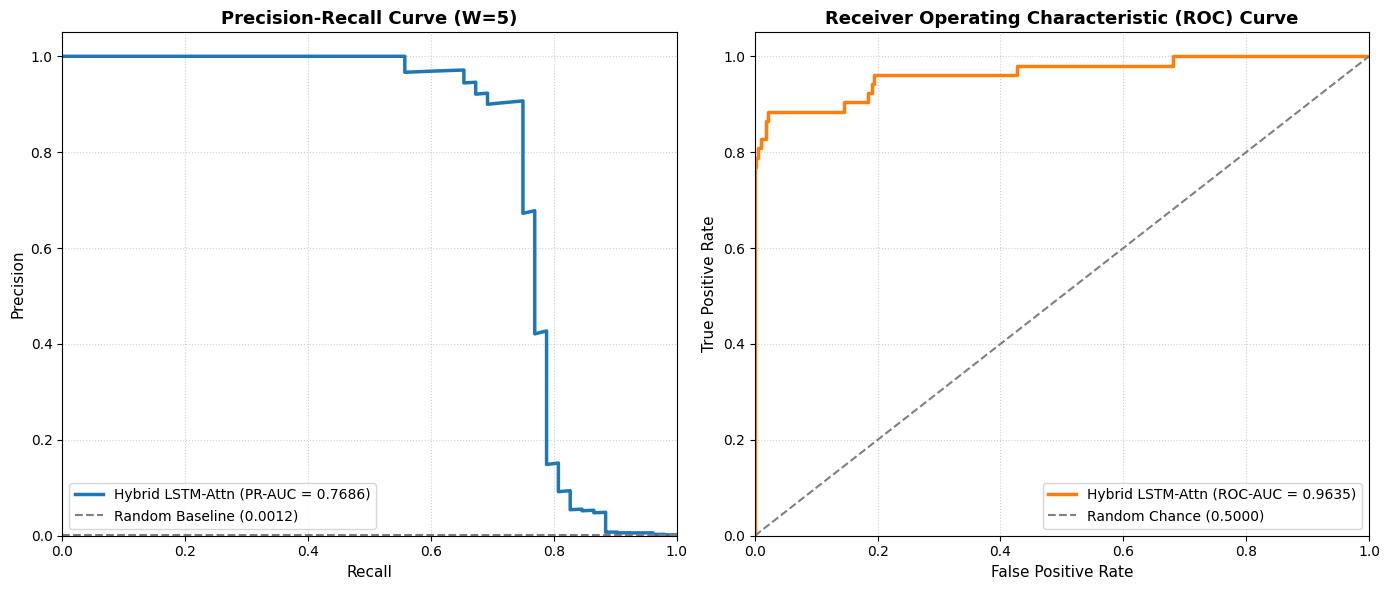


[Artifact Saved] Optimal model checkpoint saved to: best_hybrid_lstm_attn_w5.pt
[Artifact Saved] Curves figure saved to: optimal_model_curves.png


In [14]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve, auc, average_precision_score, roc_auc_score

# ==============================================================================
# Step 10: Retrain/Evaluate Optimal Model (W=5), Export Curves & Checkpoint
# ==============================================================================

# 1. Prepare sequences specifically for optimal window W=5
optimal_w = 5
print(f"Constructing sequences for optimal window size W = {optimal_w}...")

X_tr_opt, y_tr_opt = make_sequences(X_train_rows, y_train_rows, window_size=optimal_w)
X_val_opt, y_val_opt = make_sequences(X_val_rows, y_val_rows, window_size=optimal_w)
X_te_opt, y_te_opt = make_sequences(X_test_rows, y_test_rows, window_size=optimal_w)

# 2. Build DataLoaders
tr_opt_ds = TensorDataset(torch.from_numpy(X_tr_opt), torch.from_numpy(y_tr_opt).float())
val_opt_ds = TensorDataset(torch.from_numpy(X_val_opt), torch.from_numpy(y_val_opt).float())
te_opt_ds = TensorDataset(torch.from_numpy(X_te_opt), torch.from_numpy(y_te_opt).float())

tr_opt_loader = DataLoader(tr_opt_ds, batch_size=2048, shuffle=True)
val_opt_loader = DataLoader(val_opt_ds, batch_size=2048, shuffle=False)
te_opt_loader = DataLoader(te_opt_ds, batch_size=2048, shuffle=False)

# 3. Initialize model
model_optimal = LSTMAttentionClassifier(input_size=29, hidden_size=64, num_layers=2).to(device)
pos_weight_opt = torch.tensor([float(len(y_tr_opt) - y_tr_opt.sum()) / y_tr_opt.sum()]).to(device)
criterion_opt = nn.BCEWithLogitsLoss(pos_weight=pos_weight_opt)
optimizer_opt = torch.optim.Adam(model_optimal.parameters(), lr=0.001)

best_val_prauc = 0.0
best_model_state = None

print("Training optimal model (W=5)...")
for epoch in range(1, 11):
    model_optimal.train()
    running_loss = 0.0
    for Xb, yb in tr_opt_loader:
        Xb, yb = Xb.to(device), yb.to(device)
        optimizer_opt.zero_grad()
        out = model_optimal(Xb).squeeze(-1)
        loss = criterion_opt(out, yb)
        loss.backward()
        optimizer_opt.step()
        running_loss += loss.item() * len(yb)

    epoch_loss = running_loss / len(tr_opt_ds)

    # Validation step
    model_optimal.eval()
    val_preds, val_targets = [], []
    with torch.no_grad():
        for Xb, yb in val_opt_loader:
            Xb = Xb.to(device)
            probs = torch.sigmoid(model_optimal(Xb).squeeze(-1)).cpu().numpy()
            val_preds.extend(probs)
            val_targets.extend(yb.numpy())

    val_prauc = average_precision_score(val_targets, val_preds)
    if val_prauc > best_val_prauc:
        best_val_prauc = val_prauc
        best_model_state = model_optimal.state_dict().copy()

    print(f"Epoch {epoch:02d}/10 | Train Loss: {epoch_loss:.4f} | Val PR-AUC: {val_prauc:.4f}")

# 4. Evaluate on Test Set with Best Weights
model_optimal.load_state_dict(best_model_state)
model_optimal.eval()

test_preds, test_targets = [], []
with torch.no_grad():
    for Xb, yb in te_opt_loader:
        Xb = Xb.to(device)
        probs = torch.sigmoid(model_optimal(Xb).squeeze(-1)).cpu().numpy()
        test_preds.extend(probs)
        test_targets.extend(yb.numpy())

test_preds = np.array(test_preds)
test_targets = np.array(test_targets)

# 5. Compute Curves and Metrics
test_prauc = average_precision_score(test_targets, test_preds)
test_rocauc = roc_auc_score(test_targets, test_preds)

precision, recall, _ = precision_recall_curve(test_targets, test_preds)
fpr, tpr, _ = roc_curve(test_targets, test_preds)
baseline_pr = test_targets.sum() / len(test_targets)

# 6. Plot Publication-Quality Curves
plt.figure(figsize=(14, 6))

# Subplot 1: Precision-Recall Curve
plt.subplot(1, 2, 1)
plt.plot(recall, precision, color="#1f77b4", lw=2.5, label=f"Hybrid LSTM-Attn (PR-AUC = {test_prauc:.4f})")
plt.axhline(y=baseline_pr, color="gray", linestyle="--", lw=1.5, label=f"Random Baseline ({baseline_pr:.4f})")
plt.title("Precision-Recall Curve (W=5)", fontsize=13, fontweight="bold")
plt.xlabel("Recall", fontsize=11)
plt.ylabel("Precision", fontsize=11)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower left", fontsize=10)

# Subplot 2: ROC Curve
plt.subplot(1, 2, 2)
plt.plot(fpr, tpr, color="#ff7f0e", lw=2.5, label=f"Hybrid LSTM-Attn (ROC-AUC = {test_rocauc:.4f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", lw=1.5, label="Random Chance (0.5000)")
plt.title("Receiver Operating Characteristic (ROC) Curve", fontsize=13, fontweight="bold")
plt.xlabel("False Positive Rate", fontsize=11)
plt.ylabel("True Positive Rate", fontsize=11)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower right", fontsize=10)

plt.tight_layout()
plt.savefig("optimal_model_curves.png", dpi=300)
plt.show()

# 7. Save Model Weights and Configuration
save_path = "best_hybrid_lstm_attn_w5.pt"
checkpoint = {
    "model_state_dict": best_model_state,
    "input_size": 29,
    "hidden_size": 64,
    "num_layers": 2,
    "window_size": optimal_w,
    "metrics": {
        "test_pr_auc": float(test_prauc),
        "test_roc_auc": float(test_rocauc)
    }
}
torch.save(checkpoint, save_path)
print(f"\n[Artifact Saved] Optimal model checkpoint saved to: {save_path}")
print(f"[Artifact Saved] Curves figure saved to: optimal_model_curves.png")
